# CS 6220 – Homework 3: k-NN, Perceptron, Single Neuron
Structure of this notebook:
1. **Part 1 – k-NN**: distance functions, `knn_predict`, decision-boundary plot, training/LOOCV error, experiments (Q3–Q5).
2. **Part 2 – Neural network**: `train_perceptron` (Q7–Q8) and `train_neuron` (Q9).
3. **Demo MLP** (Q10–Q12) is run in the separate demo notebook `HW3-gradient_flow_mnist.ipynb`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.datasets import make_moons
from matplotlib import animation
from IPython.display import HTML, display

plt.rcParams['animation.embed_limit'] = 60  # MB, so the jshtml animations fit

# Dataset (same seed for everyone, as required)
np.random.seed(42)
X, y = make_moons(n_samples=200, noise=0.15)
print(type(X), X.shape, X.dtype, '|', type(y), y.shape, y.dtype)
print('class counts:', Counter(y.tolist()))

<class 'numpy.ndarray'> (200, 2) float64 | <class 'numpy.ndarray'> (200,) int64
class counts: Counter({0: 100, 1: 100})


## Part 1: k-Nearest Neighbor
### 1.1 Distance measure
One general $L_p$ distance; `p=1` is Manhattan, `p=2` is Euclidean. `lp_distance(p)` returns a function `d(v1, v2) -> float`, which is what `knn_predict` expects as `distance_func`.

In [2]:
def lp_distance(p):
    # Returns a distance function for the L_p norm: (sum_i |v1_i - v2_i|^p)^(1/p)
    def dist(v1, v2):
        return float(np.sum(np.abs(np.asarray(v1) - np.asarray(v2)) ** p) ** (1.0 / p))
    dist.__name__ = {1: 'manhattan', 2: 'euclidean'}.get(p, f'L{p}')
    return dist

euclidean = lp_distance(2)
manhattan = lp_distance(1)
print(euclidean([0, 0], [3, 4]), manhattan([0, 0], [3, 4]))  # 5.0, 7.0

5.0 7.0


### 1.2 `knn_predict`
- `X_train` is an `(n, 2)` float ndarray and `y_train` an `(n,)` int ndarray, exactly as returned by `make_moons`.
- `X_test` is one record (a row `X[i]`, shape `(2,)`), `y_test` its label (`y[i]`). `y_test` is not needed to predict; it is accepted to match the required signature.
- Neighbor search: brute force – compute the distance to every training record, then a stable sort (exact k-NN).
- **Tie-breaking** (two classes with the same number of votes): pick the tied class whose neighbors have the **smallest summed distance** to the test record (i.e. the "closer" class). If that is still tied, use the class of the single nearest neighbor. Ties between equidistant records at the k-th position are resolved by the stable sort (lower index first).

In [3]:
def majority_vote(labels, dists):
    # labels/dists of the k nearest neighbors, sorted by distance (ascending)
    votes = Counter(labels.tolist())
    top = max(votes.values())
    tied = [c for c, v in votes.items() if v == top]
    if len(tied) == 1:
        return tied[0], votes
    # Tie: class with the smallest total distance among its neighbors wins
    sums = {c: dists[labels == c].sum() for c in tied}
    best = min(sums.values())
    tied2 = [c for c in tied if np.isclose(sums[c], best)]
    if len(tied2) == 1:
        return tied2[0], votes
    # Still tied: class of the nearest neighbor (labels are sorted by distance)
    for lab in labels:
        if lab in tied2:
            return int(lab), votes


def knn_neighbors(X_train, x_test, k, distance_func):
    # Exact search: distance to every training record, then stable sort
    dists = np.array([distance_func(x, x_test) for x in X_train])
    order = np.argsort(dists, kind='stable')[:k]
    return order, dists[order]


def knn_predict(X_train, y_train, X_test, y_test, k, distance_func, return_votes=False):
    # X_test, y_test: a single record (y_test unused for prediction, kept for the required signature)
    idx, d = knn_neighbors(X_train, X_test, k, distance_func)
    pred, votes = majority_vote(y_train[idx], d)
    return (int(pred), votes) if return_votes else int(pred)

# Quick check: predict the first record from the rest
print(knn_predict(X[1:], y[1:], X[0], y[0], 3, euclidean), 'true:', y[0])

0 true: 0


### 1.3 Decision-boundary visualization
A 100×100 grid over the data range is classified with `knn_predict`; the predicted class is drawn as a filled background (`contourf`), training records are drawn on top with class-specific color and marker.

In [4]:
def plot_knn(X_train, y_train, k, distance_func, grid=100, ax=None, title=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5))
    pad = 0.5
    xs = np.linspace(X_train[:, 0].min() - pad, X_train[:, 0].max() + pad, grid)
    ys = np.linspace(X_train[:, 1].min() - pad, X_train[:, 1].max() + pad, grid)
    xx, yy = np.meshgrid(xs, ys)
    Z = np.array([knn_predict(X_train, y_train, p, None, k, distance_func)
                  for p in np.c_[xx.ravel(), yy.ravel()]]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], colors=['#9ecae1', '#fdae6b'], alpha=0.6)
    for c, col, m in [(0, 'tab:blue', 'o'), (1, 'tab:orange', 's')]:
        ax.scatter(*X_train[y_train == c].T, c=col, marker=m, edgecolor='k', s=25, label=f'class {c}')
    ax.set_xlabel('x1'); ax.set_ylabel('x2'); ax.legend(loc='upper right')
    ax.set_title(title or f'{k}-NN ({distance_func.__name__})')
    return ax

### 1.4 Training error and LOOCV test error
- **Training error**: predict every training record using the full training set (the record itself is included, so for k=1 it is its own neighbor).
- **Test error (LOOCV)**: for every record R, train on all other records and predict R.

`knn_errors` uses `knn_predict` directly. `knn_error_curve` (used for the k-sweep in Q5d) computes the pairwise distance matrix once with the same `distance_func` and reuses the same `majority_vote`, so results are identical but it is fast enough to try every k.

In [5]:
def knn_errors(X, y, k, distance_func):
    n = len(X)
    train_wrong = sum(knn_predict(X, y, X[i], y[i], k, distance_func) != y[i] for i in range(n))
    test_wrong = 0
    for i in range(n):                        # LOOCV
        mask = np.arange(n) != i
        test_wrong += knn_predict(X[mask], y[mask], X[i], y[i], k, distance_func) != y[i]
    return train_wrong / n, test_wrong / n


def knn_error_curve(X, y, ks, distance_func):
    n = len(X)
    D = np.array([[distance_func(X[i], X[j]) for j in range(n)] for i in range(n)])
    tr, te = [], []
    for k in ks:
        wrong_tr = wrong_te = 0
        for i in range(n):
            o = np.argsort(D[i], kind='stable')                    # includes i itself
            p_tr, _ = majority_vote(y[o[:k]], D[i, o[:k]])
            o_loo = o[o != i][:min(k, n - 1)]                      # leave i out
            p_te, _ = majority_vote(y[o_loo], D[i, o_loo])
            wrong_tr += p_tr != y[i]; wrong_te += p_te != y[i]
        tr.append(wrong_tr / n); te.append(wrong_te / n)
    return np.array(tr), np.array(te)

for k in [1, 3, 5, 10]:
    tr, te = knn_errors(X, y, k, euclidean)
    print(f'k={k:2d}  train error={tr:.3f}  LOOCV test error={te:.3f}')

k= 1  train error=0.000  LOOCV test error=0.020
k= 3  train error=0.010  LOOCV test error=0.010
k= 5  train error=0.005  LOOCV test error=0.005
k=10  train error=0.005  LOOCV test error=0.010


### Q3: Predictions for three test points

In [6]:
test_points = [(0.40, 0.45), (0.08, 0.78), (0.75, -0.15)]
q3_rows = []
for tp in test_points:
    for dfun in [euclidean, manhattan]:
        for k in [1, 3, 5]:
            pred, votes = knn_predict(X, y, np.array(tp), None, k, dfun, return_votes=True)
            q3_rows.append((tp, dfun.__name__, k, votes.get(0, 0), votes.get(1, 0), pred))
            print(f'{str(tp):14s} {dfun.__name__:9s} k={k}  votes c0={votes.get(0,0)} c1={votes.get(1,0)}  -> class {pred}')

(0.4, 0.45)    euclidean k=1  votes c0=1 c1=0  -> class 0
(0.4, 0.45)    euclidean k=3  votes c0=1 c1=2  -> class 1
(0.4, 0.45)    euclidean k=5  votes c0=1 c1=4  -> class 1
(0.4, 0.45)    manhattan k=1  votes c0=1 c1=0  -> class 0
(0.4, 0.45)    manhattan k=3  votes c0=1 c1=2  -> class 1
(0.4, 0.45)    manhattan k=5  votes c0=1 c1=4  -> class 1
(0.08, 0.78)   euclidean k=1  votes c0=0 c1=1  -> class 1
(0.08, 0.78)   euclidean k=3  votes c0=2 c1=1  -> class 0
(0.08, 0.78)   euclidean k=5  votes c0=4 c1=1  -> class 0
(0.08, 0.78)   manhattan k=1  votes c0=0 c1=1  -> class 1
(0.08, 0.78)   manhattan k=3  votes c0=2 c1=1  -> class 0
(0.08, 0.78)   manhattan k=5  votes c0=4 c1=1  -> class 0
(0.75, -0.15)  euclidean k=1  votes c0=1 c1=0  -> class 0
(0.75, -0.15)  euclidean k=3  votes c0=1 c1=2  -> class 1
(0.75, -0.15)  euclidean k=5  votes c0=2 c1=3  -> class 1
(0.75, -0.15)  manhattan k=1  votes c0=0 c1=1  -> class 1
(0.75, -0.15)  manhattan k=3  votes c0=1 c1=2  -> class 1
(0.75, -0.15) 

In [7]:
# Show the nearest neighbors behind those votes (helps explain the differences)
for tp in test_points:
    for dfun in [euclidean, manhattan]:
        idx, d = knn_neighbors(X, np.array(tp), 5, dfun)
        print(tp, dfun.__name__, 'nearest 5 (label, dist):', [(int(y[i]), round(float(dd), 3)) for i, dd in zip(idx, d)])

(0.4, 0.45) euclidean nearest 5 (label, dist): [(0, 0.197), (1, 0.214), (1, 0.243), (1, 0.254), (1, 0.264)]
(0.4, 0.45) manhattan nearest 5 (label, dist): [(0, 0.218), (1, 0.277), (1, 0.29), (1, 0.335), (1, 0.354)]
(0.08, 0.78) euclidean nearest 5 (label, dist): [(1, 0.101), (0, 0.168), (0, 0.173), (0, 0.179), (0, 0.18)]
(0.08, 0.78) manhattan nearest 5 (label, dist): [(1, 0.143), (0, 0.203), (0, 0.219), (0, 0.228), (0, 0.249)]
(0.75, -0.15) euclidean nearest 5 (label, dist): [(0, 0.105), (1, 0.109), (1, 0.122), (0, 0.136), (1, 0.204)]
(0.75, -0.15) manhattan nearest 5 (label, dist): [(1, 0.121), (0, 0.147), (1, 0.164), (0, 0.174), (1, 0.247)]


### Q3d: Minimal example where Euclidean and Manhattan disagree
Test record at the origin; A=(2, 0) is class 0 and B=(1.2, 1.2) is class 1, k=1.
- Euclidean: d(A)=2.0, d(B)=√2.88≈1.70 → B is nearest → class 1.
- Manhattan: d(A)=2.0, d(B)=2.4 → A is nearest → class 0.

In [8]:
X_mini = np.array([[2.0, 0.0], [1.2, 1.2]]); y_mini = np.array([0, 1]); t = np.array([0.0, 0.0])
for dfun in [euclidean, manhattan]:
    print(dfun.__name__, [round(dfun(x, t), 3) for x in X_mini], '-> class', knn_predict(X_mini, y_mini, t, None, 1, dfun))

euclidean [2.0, 1.697] -> class 1
manhattan [2.0, 2.4] -> class 0


### Q4: 1-NN vs 10-NN decision boundaries

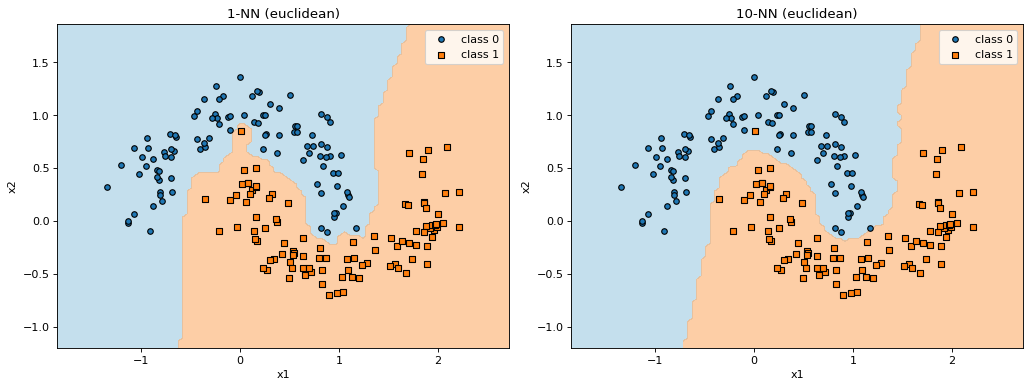

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_knn(X, y, 1, euclidean, ax=axes[0])
plot_knn(X, y, 10, euclidean, ax=axes[1])
plt.tight_layout(); plt.savefig('fig_q4.png', dpi=110); plt.show()

### Q5c: Data where zero training error is impossible
Two records with identical inputs but different labels. Whatever k is, both get the same neighbors and hence the same prediction, so one of them is always wrong.

In [10]:
X_c = np.array([[0.0, 0.0], [0.0, 0.0]]); y_c = np.array([0, 1])
for k in [1, 2]:
    preds = [knn_predict(X_c, y_c, X_c[i], y_c[i], k, euclidean) for i in range(2)]
    print(f'k={k}: predictions {preds}, true {y_c.tolist()}, training error {np.mean(np.array(preds) != y_c):.2f}')

k=1: predictions [0, 0], true [0, 1], training error 0.50
k=2: predictions [0, 0], true [0, 1], training error 0.50


### Q5d: Training and LOOCV test error for k = 1 … 200 (Euclidean)

best k by LOOCV: 5 test error: 0.005
k=  1  train=0.000  test=0.020
k=  2  train=0.000  test=0.020
k=  5  train=0.005  test=0.005
k= 10  train=0.005  test=0.010
k= 20  train=0.015  test=0.020
k= 50  train=0.045  test=0.050
k=100  train=0.170  test=0.175
k=150  train=0.285  test=0.285
k=198  train=0.315  test=0.325
k=199  train=0.325  test=1.000
k=200  train=0.170  test=1.000


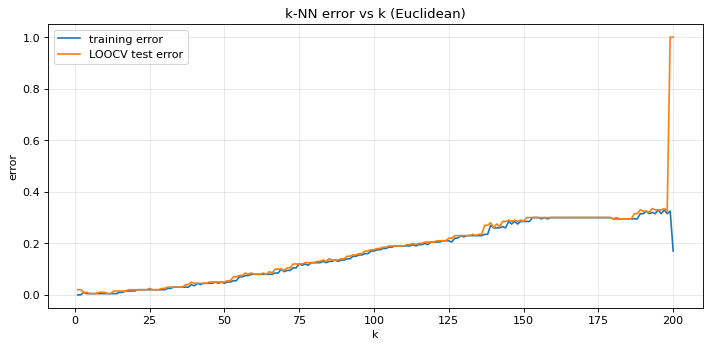

In [11]:
ks = np.arange(1, len(X) + 1)
tr_curve, te_curve = knn_error_curve(X, y, ks, euclidean)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(ks, tr_curve, label='training error')
ax.plot(ks, te_curve, label='LOOCV test error')
ax.set_xlabel('k'); ax.set_ylabel('error'); ax.set_title('k-NN error vs k (Euclidean)'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig('fig_q5d.png', dpi=110); plt.show()
best = ks[np.argmin(te_curve)]
print('best k by LOOCV:', best, 'test error:', te_curve.min())
for k in [1, 2, 5, 10, 20, 50, 100, 150, 198, 199, 200]:
    print(f'k={k:3d}  train={tr_curve[k-1]:.3f}  test={te_curve[k-1]:.3f}')

## Part 2: Neural Network
### 2.1 Perceptron training rule
Prediction: $\hat y = 1$ if $w_1x_1 + w_2x_2 + b > 0$ else $0$. Update for one record: $w_i \leftarrow w_i + \eta (y-\hat y) x_i$, $b \leftarrow b + \eta (y-\hat y)$. Weights only change when the record is misclassified.

In [12]:
def perceptron_predict(x1, x2, w1, w2, b):
    return 1 if w1 * x1 + w2 * x2 + b > 0 else 0


def train_perceptron(training_record, learning_rate, w1, w2, b):
    x1, x2, y_true = training_record
    err = y_true - perceptron_predict(x1, x2, w1, w2, b)   # 0 if correct, +1/-1 if wrong
    w1 += learning_rate * err * x1
    w2 += learning_rate * err * x2
    b += learning_rate * err
    return w1, w2, b


def perceptron_error(data, w1, w2, b):
    return np.mean([perceptron_predict(x1, x2, w1, w2, b) != yy for x1, x2, yy in data])


def plot_boundary(data, w1, w2, b, ax, title=''):
    d = np.array(data)
    gx, gy = np.meshgrid(np.linspace(0, 4, 200), np.linspace(0, 4, 200))
    ax.contourf(gx, gy, (w1 * gx + w2 * gy + b > 0).astype(int), levels=[-0.5, 0.5, 1.5],
                colors=['#9ecae1', '#fdae6b'], alpha=0.4)   # shaded = predicted class
    for c, col, m in [(0, 'tab:blue', 'o'), (1, 'tab:orange', 's')]:
        ax.scatter(*d[d[:, 2] == c][:, :2].T, c=col, marker=m, edgecolor='k', label=f'class {c}')
    xs = np.linspace(0, 4, 50)
    if abs(w2) > 1e-12:
        ax.plot(xs, -(w1 * xs + b) / w2, 'k--')
    elif abs(w1) > 1e-12:
        ax.axvline(-b / w1, color='k', ls='--')
    ax.set_xlim(0, 4); ax.set_ylim(0, 4); ax.set_xlabel('x1'); ax.set_ylabel('x2'); ax.set_title(title, fontsize=9)


def run_perceptron(data, w, lr, epochs):
    # Calls train_perceptron record-by-record; logs (w1, w2, b, error on whole dataset) after every call
    log = [(*w, perceptron_error(data, *w))]
    for _ in range(epochs):
        for rec in data:
            w = train_perceptron(rec, lr, *w)
            log.append((*w, perceptron_error(data, *w)))
    return log

### Q7: Linearly separable data

In [13]:
data7 = [(0.9, 1.1, 0), (1.0, 0.8, 0), (1.1, 1.0, 0), (0.8, 1.0, 0), (1.2, 1.1, 0),
         (3.1, 2.9, 1), (3.0, 3.2, 1), (2.9, 3.0, 1), (3.2, 3.1, 1), (3.0, 2.8, 1)]
# Bad start: predicts 1 near (1,1) and 0 near (3,3)  ->  all 10 records wrong
w0 = (-1.0, -1.0, 4.0)
print('initial error:', perceptron_error(data7, *w0))
log7 = run_perceptron(data7, w0, lr=0.1, epochs=20)
for i, (w1, w2, b, e) in enumerate(log7):
    if i <= 20 or i % 10 == 0 or 160 <= i <= 175:
        print(f'call {i:2d}: w1={w1:+.2f} w2={w2:+.2f} b={b:+.2f}  error={e:.1f}')

initial error: 1.0
call  0: w1=-1.00 w2=-1.00 b=+4.00  error=1.0
call  1: w1=-1.09 w2=-1.11 b=+3.90  error=1.0
call  2: w1=-1.19 w2=-1.19 b=+3.80  error=1.0
call  3: w1=-1.30 w2=-1.29 b=+3.70  error=1.0
call  4: w1=-1.38 w2=-1.39 b=+3.60  error=1.0
call  5: w1=-1.50 w2=-1.50 b=+3.50  error=1.0
call  6: w1=-1.19 w2=-1.21 b=+3.60  error=1.0
call  7: w1=-0.89 w2=-0.89 b=+3.70  error=1.0
call  8: w1=-0.60 w2=-0.59 b=+3.80  error=0.5
call  9: w1=-0.60 w2=-0.59 b=+3.80  error=0.5
call 10: w1=-0.60 w2=-0.59 b=+3.80  error=0.5
call 11: w1=-0.69 w2=-0.70 b=+3.70  error=1.0
call 12: w1=-0.79 w2=-0.78 b=+3.60  error=1.0
call 13: w1=-0.90 w2=-0.88 b=+3.50  error=1.0
call 14: w1=-0.98 w2=-0.98 b=+3.40  error=1.0
call 15: w1=-1.10 w2=-1.09 b=+3.30  error=1.0
call 16: w1=-0.79 w2=-0.80 b=+3.40  error=1.0
call 17: w1=-0.49 w2=-0.48 b=+3.50  error=0.5
call 18: w1=-0.49 w2=-0.48 b=+3.50  error=0.5
call 19: w1=-0.49 w2=-0.48 b=+3.50  error=0.5
call 20: w1=-0.49 w2=-0.48 b=+3.50  error=0.5
call 30: w1=-0.

first call with zero training error: 172 (0.15000000000000066, -0.020000000000000434, -0.30000000000000243, np.float64(0.0))


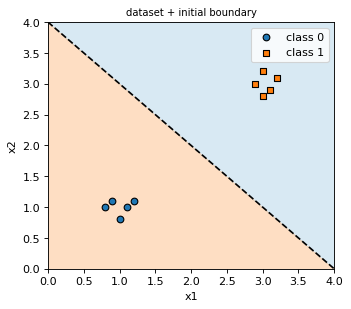

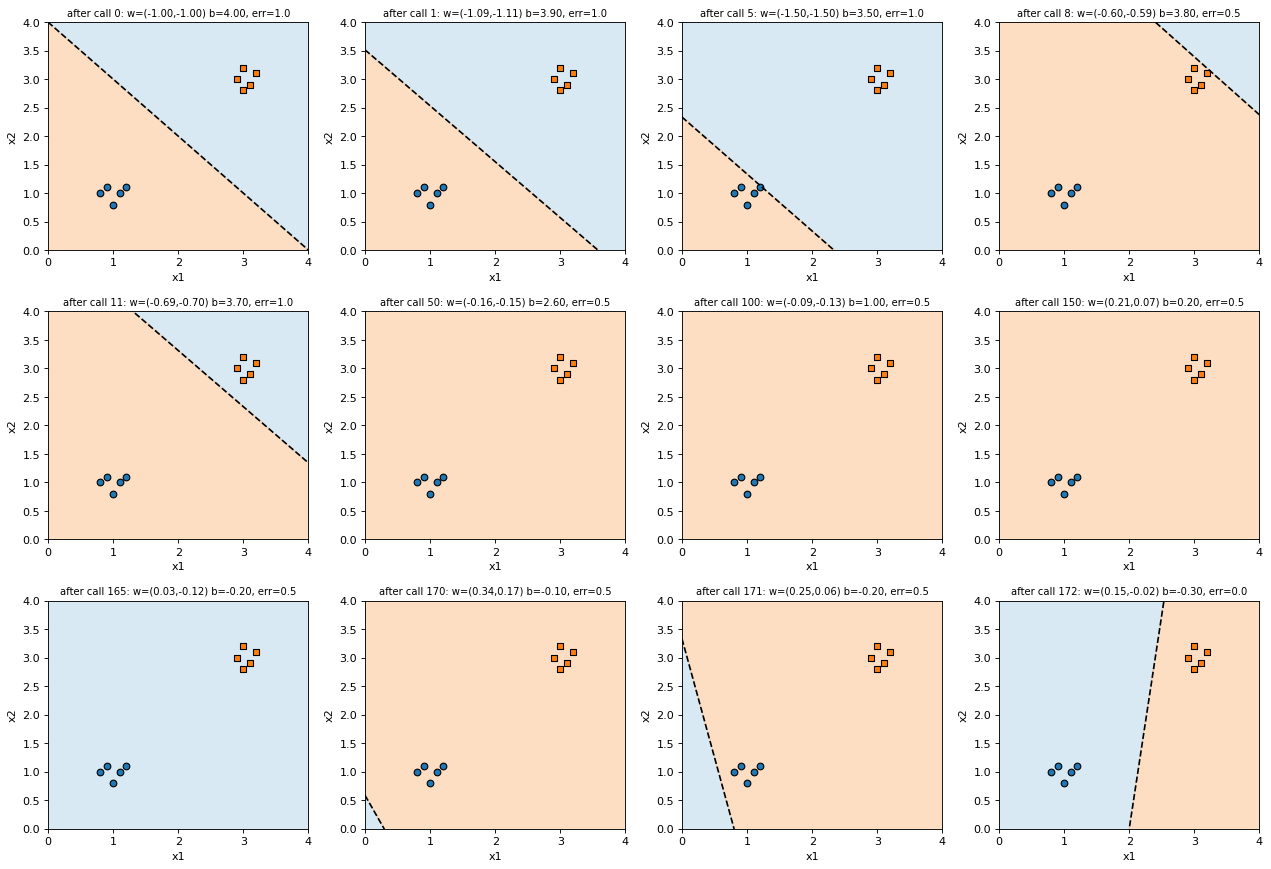

In [14]:
fig, ax = plt.subplots(figsize=(4.5, 4)); plot_boundary(data7, *w0, ax, 'dataset + initial boundary')
ax.legend(); plt.tight_layout(); plt.show()

first_zero = next(i for i, r in enumerate(log7) if r[3] == 0)
show = [0, 1, 5, 8, 11, 50, 100, 150, 165, 170, 171, first_zero]   # early calls + the last calls before convergence
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, i in zip(axes.ravel(), show):
    w1, w2, b, e = log7[i]
    plot_boundary(data7, w1, w2, b, ax, f'after call {i}: w=({w1:.2f},{w2:.2f}) b={b:.2f}, err={e:.1f}')
plt.tight_layout(); plt.savefig('fig_q7.png', dpi=100); plt.show()
print('first call with zero training error:', first_zero, log7[first_zero])

### Q8: Add (1.0, 1.0, 1)

min training error: 0.09090909090909091 at call 189 (0.15000000000000066, -0.020000000000000434, -0.30000000000000243, np.float64(0.09090909090909091))
error over the last 22 calls (2 epochs): [0.18 0.18 0.18 0.18 0.09 0.09 0.09 0.09 0.09 0.09 0.09 0.09 0.09 0.09
 0.09 0.09 0.09 0.09 0.09 0.09 0.09 0.27]


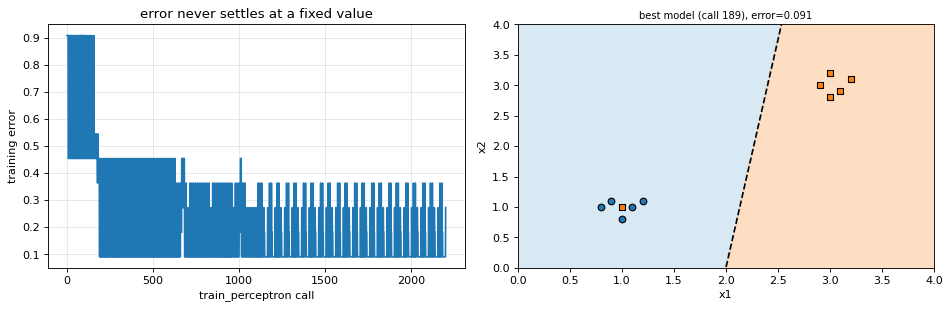

In [15]:
data8 = data7 + [(1.0, 1.0, 1)]
log8 = run_perceptron(data8, w0, lr=0.1, epochs=200)
errs8 = np.array([r[3] for r in log8])
best8 = int(np.argmin(errs8))
print('min training error:', errs8.min(), 'at call', best8, log8[best8])
print('error over the last 22 calls (2 epochs):', np.round(errs8[-22:], 2))
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(errs8); a1.set_xlabel('train_perceptron call'); a1.set_ylabel('training error'); a1.grid(alpha=.3)
a1.set_title('error never settles at a fixed value')
plot_boundary(data8, *log8[best8][:3], a2, f'best model (call {best8}), error={errs8[best8]:.3f}')
plt.tight_layout(); plt.savefig('fig_q8.png', dpi=100); plt.show()

### 2.2 Single neuron: `train_neuron`
Model: $\hat y = a(z)$, $z = wx + b$. For one record, by the chain rule
$\frac{\partial C}{\partial w} = C'(\hat y, y)\, a'(z)\, x$, $\frac{\partial C}{\partial b} = C'(\hat y, y)\, a'(z)$, then $w \leftarrow w - \eta\,\partial C/\partial w$.
- Squared error $C=\tfrac12(\hat y-y)^2$: $C' = \hat y - y$.
- Cross-entropy $C=-[y\ln\hat y + (1-y)\ln(1-\hat y)]$: $C' = \frac{\hat y - y}{\hat y(1-\hat y)}$ (prediction clipped to $(\epsilon, 1-\epsilon)$ to avoid division by zero).
- ReLU derivative at 0 is set to 0. `linear` (identity) is added for Q9e.

The function returns the updated `w, b` **and** the gradients (Q9d).

In [16]:
EPS = 1e-7
ACT = {
    'sigmoid': (lambda z: 1 / (1 + np.exp(-z)),            lambda z: (1 / (1 + np.exp(-z))) * (1 - 1 / (1 + np.exp(-z)))),
    'tanh':    (np.tanh,                                     lambda z: 1 - np.tanh(z) ** 2),
    'relu':    (lambda z: np.maximum(0.0, z),                lambda z: 1.0 if z > 0 else 0.0),
    'linear':  (lambda z: z,                                 lambda z: 1.0),
}
COST = {
    'squared_error': (lambda yh, y: 0.5 * (yh - y) ** 2,
                      lambda yh, y: yh - y),
    'cross_entropy': (lambda yh, y: -(y * np.log(np.clip(yh, EPS, 1 - EPS)) + (1 - y) * np.log(1 - np.clip(yh, EPS, 1 - EPS))),
                      lambda yh, y: (np.clip(yh, EPS, 1 - EPS) - y) / (np.clip(yh, EPS, 1 - EPS) * (1 - np.clip(yh, EPS, 1 - EPS)))),
}


def train_neuron(training_record, learning_rate, w, b, cost_derivative, activation_derivative, activation):
    # activation (forward function) is needed to compute y_hat; derivatives are passed as required
    x, y_true = training_record
    z = w * x + b
    y_hat = activation(z)
    delta = cost_derivative(y_hat, y_true) * activation_derivative(z)   # dC/dz
    grad_w, grad_b = delta * x, delta
    w -= learning_rate * grad_w
    b -= learning_rate * grad_b
    return w, b, grad_w, grad_b

### Q9: Data (HW2 generator) and training loop
**Note:** replace `generate_data` with your own HW2 generator if it differs. Here: x uniform in [0,1], y = f(x) + Gaussian noise with std = noise level.

In [17]:
def generate_data(f, n, x_min, x_max, noise, seed=0):
    rng = np.random.default_rng(seed)
    x = rng.uniform(x_min, x_max, n)
    return x, f(x) + rng.normal(0, noise, n)

f_true = lambda x: 2 * x + 3
x9, y9 = generate_data(f_true, 100, 0, 1, 0.1, seed=0)


def fit_neuron(act, cost, lr=0.01, epochs=60, w=0.1, b=0.1, seed=0):
    # One epoch = one pass over the shuffled records, one train_neuron call per record.
    a, da = ACT[act]; C, dC = COST[cost]
    rng = np.random.default_rng(seed)
    hist = {'w': [w], 'b': [b], 'mse': [np.mean((a(w * x9 + b) - y9) ** 2)], 'gw': [], 'gb': [], 'gw_ep': [], 'gb_ep': []}
    with np.errstate(all='ignore'):
        for ep in range(epochs):
            for i in rng.permutation(len(x9)):
                w, b, gw, gb = train_neuron((x9[i], y9[i]), lr, w, b, dC, da, a)
                hist['gw'].append(gw); hist['gb'].append(gb)
            n = len(x9)
            hist['gw_ep'].append(np.mean(hist['gw'][-n:])); hist['gb_ep'].append(np.mean(hist['gb'][-n:]))
            hist['w'].append(w); hist['b'].append(b)
            hist['mse'].append(np.mean((a(w * x9 + b) - y9) ** 2))
    return hist


def animate(hist, act, title):
    a = ACT[act][0]; xs = np.linspace(0, 1, 50)
    fig, ax = plt.subplots(figsize=(5, 3.5), dpi=72)
    ax.scatter(x9, y9, s=8, c='gray', alpha=.6, label='data'); ax.plot(xs, f_true(xs), 'g', label='true y=2x+3')
    line, = ax.plot([], [], 'r', lw=2, label='model'); txt = ax.text(0.02, 0.92, '', transform=ax.transAxes)
    ax.set_ylim(-1.5, 6); ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_title(title, fontsize=9); ax.legend(loc='lower right', fontsize=7)
    def upd(i):
        with np.errstate(all='ignore'):
            line.set_data(xs, a(hist['w'][i] * xs + hist['b'][i]))
        txt.set_text(f"epoch {i}  MSE={hist['mse'][i]:.3f}"); return line, txt
    ani = animation.FuncAnimation(fig, upd, frames=len(hist['w']), interval=100)
    plt.close(fig)
    return HTML(ani.to_jshtml())

### Q9a: All activation × cost combinations (lr = 0.01, 60 epochs)

In [18]:
combos = [(a, c) for a in ['sigmoid', 'tanh', 'relu'] for c in ['squared_error', 'cross_entropy']]
H = {combo: fit_neuron(*combo) for combo in combos}
for (a, c), h in H.items():
    print(f'{a:8s} {c:14s} final w={h["w"][-1]:8.3f} b={h["b"][-1]:8.3f}  final MSE={h["mse"][-1]:.4f}')

sigmoid  squared_error  final w=   2.203 b=   4.240  final MSE=9.9408
sigmoid  cross_entropy  final w=   8.466 b=  18.725  final MSE=9.9120
tanh     squared_error  final w=   1.477 b=   3.011  final MSE=9.9193
tanh     cross_entropy  final w=   4.471 b=  10.417  final MSE=9.9120
relu     squared_error  final w=   1.985 b=   2.999  final MSE=0.0094
relu     cross_entropy  final w=1124965178.383 b=1852014554.144  final MSE=6211350511906609152.0000


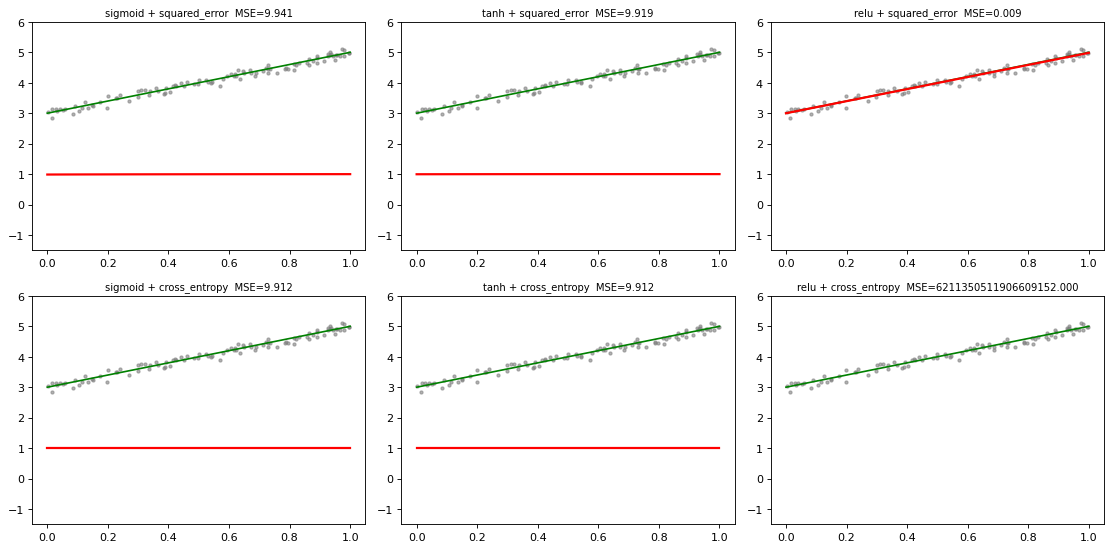

In [19]:
# Static summary: final model of every combination
xs = np.linspace(0, 1, 50)
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (combo, h) in zip(axes.T.ravel(), H.items()):
    a = ACT[combo[0]][0]
    ax.scatter(x9, y9, s=8, c='gray', alpha=.6); ax.plot(xs, f_true(xs), 'g')
    with np.errstate(all='ignore'):
        ax.plot(xs, a(h['w'][-1] * xs + h['b'][-1]), 'r', lw=2)
    ax.set_ylim(-1.5, 6); ax.set_title(f'{combo[0]} + {combo[1]}  MSE={h["mse"][-1]:.3f}', fontsize=9)
plt.tight_layout(); plt.savefig('fig_q9a.png', dpi=100); plt.show()

In [20]:
display(animate(H[('relu', 'squared_error')], 'relu', 'ReLU + squared error, lr=0.01'))

In [21]:
display(animate(H[('sigmoid', 'squared_error')], 'sigmoid', 'sigmoid + squared error, lr=0.01'))

In [22]:
display(animate(H[('relu', 'cross_entropy')], 'relu', 'ReLU + cross-entropy, lr=0.01'))

### Q9c: Learning rates (ReLU + squared error)

lr=0.001  final w=     1.899 b=     3.049 MSE=0.01011
lr=0.01   final w=     1.985 b=     2.999 MSE=0.009405
lr=0.1    final w=     1.985 b=     3.002 MSE=0.009405
lr=1      final w=     1.917 b=     3.194 MSE=0.03425
lr=10     final w=    -198.1 b=    -411.3 MSE=17.09


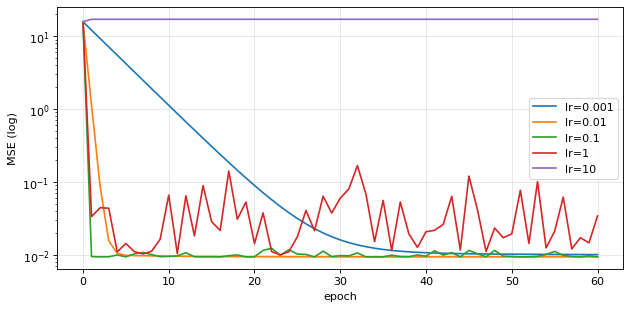

In [23]:
lrs = [0.001, 0.01, 0.1, 1, 10]
HL = {lr: fit_neuron('relu', 'squared_error', lr=lr, epochs=60) for lr in lrs}
fig, ax = plt.subplots(figsize=(8, 4))
for lr, h in HL.items():
    ax.plot(h['mse'], label=f'lr={lr}')
    print(f'lr={lr:<6} final w={h["w"][-1]:10.4g} b={h["b"][-1]:10.4g} MSE={h["mse"][-1]:.4g}')
ax.set_yscale('log'); ax.set_xlabel('epoch'); ax.set_ylabel('MSE (log)'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig('fig_q9c.png', dpi=100); plt.show()

In [24]:
display(animate(HL[0.001], 'relu', 'extreme case: lr=0.001 (too slow)'))
display(animate(HL[10], 'relu', 'extreme case: lr=10'))

### Q9d: Gradients for w and b

epoch-mean |dC/db| at epochs 1,5,10,30,60: [np.float64(2.1684), np.float64(0.0114), np.float64(0.0012), np.float64(0.0015), np.float64(0.0023)]


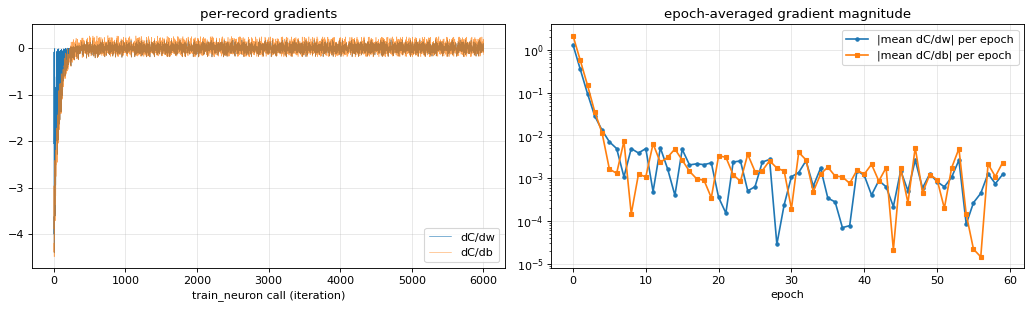

In [25]:
h = H[('relu', 'squared_error')]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
a1.plot(h['gw'], lw=.5, label='dC/dw'); a1.plot(h['gb'], lw=.5, alpha=.7, label='dC/db')
a1.set_xlabel('train_neuron call (iteration)'); a1.set_title('per-record gradients'); a1.legend(); a1.grid(alpha=.3)
a2.plot(np.abs(h['gw_ep']), 'o-', ms=3, label='|mean dC/dw| per epoch'); a2.plot(np.abs(h['gb_ep']), 's-', ms=3, label='|mean dC/db| per epoch')
a2.set_yscale('log'); a2.set_xlabel('epoch'); a2.set_title('epoch-averaged gradient magnitude'); a2.legend(); a2.grid(alpha=.3)
plt.tight_layout(); plt.savefig('fig_q9d.png', dpi=100); plt.show()
print('epoch-mean |dC/db| at epochs 1,5,10,30,60:', [round(abs(h['gb_ep'][e-1]), 4) for e in [1, 5, 10, 30, 60]])

### Q9e: Linear activation

In [26]:
for c in ['squared_error', 'cross_entropy']:
    hl = fit_neuron('linear', c)
    print(f'linear + {c:14s}: w={hl["w"][-1]:.3f} b={hl["b"][-1]:.3f} MSE={hl["mse"][-1]:.4f}')
hr = H[('relu', 'squared_error')]
print(f'relu   + squared_error : w={hr["w"][-1]:.3f} b={hr["b"][-1]:.3f} MSE={hr["mse"][-1]:.4f}')
# Closed-form least squares for reference
A = np.c_[x9, np.ones_like(x9)]; print('least-squares w,b:', np.linalg.lstsq(A, y9, rcond=None)[0].round(3))

linear + squared_error : w=1.985 b=2.999 MSE=0.0094
linear + cross_entropy : w=1124965178.383 b=1852014554.144 MSE=6211350511906609152.0000
relu   + squared_error : w=1.985 b=2.999 MSE=0.0094
least-squares w,b: [1.987 2.999]


## Q10–Q12: Demo MLP
These are run in the separate demo notebook `HW3-gradient_flow_mnist.ipynb` (needs `torch`, `torchvision`). Configurations used for Q12:
1. Default: `ACTIVATIONS = ['sigmoid']*5`, `COST_FUNCTION = 'mse'`
2. `ACTIVATIONS = ['sigmoid']*4 + ['identity']`, `COST_FUNCTION = 'cross_entropy'`
3. `ACTIVATIONS = ['relu']*4 + ['identity']`, `COST_FUNCTION = 'cross_entropy'`